# Part B · Smoothing, windows and panel shape, computed

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 4

Three decisions quietly decide what a time-series chart says: the window, the smoother and the frame.
Here each one is computed instead of eyeballed, on the **cleaned daily session series** from Part D. The
cleaning lives in [`sessions_clean.py`](sessions_clean.py), so this notebook and Part D's figure use
exactly the same numbers.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose

import sessions_clean
import tslib
from vizlib import PALETTE, save_fig, style_defaults

CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
plt.rcParams["date.converter"] = "concise"
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
SOURCE = "Source: synthetic course data, CDB601220 Week 4."


def save(fig, name, note=""):
    save_fig(fig, CHARTS / name, note=f"{note}  {SOURCE}".strip())


daily = sessions_clean.load_daily()
print(f"{len(daily)} days, {daily.index.min().date()} to {daily.index.max().date()}, "
      f"{daily.isna().sum()} days with no data (left as NaN)")
tslib.audit_index(daily.dropna(), "D")

518 days, 2024-04-01 to 2025-08-31, 13 days with no data (left as NaN)


{'dtype_ok': True,
 'monotonic': True,
 'n_rows': 505,
 'n_duplicated': 0,
 'n_missing': 13,
 'missing_dates': ['2024-05-18 00:00:00',
  '2024-07-02 00:00:00',
  '2024-07-03 00:00:00',
  '2024-09-27 00:00:00',
  '2024-11-11 00:00:00',
  '2024-12-25 00:00:00',
  '2025-01-01 00:00:00',
  '2025-02-14 00:00:00',
  '2025-03-30 00:00:00',
  '2025-03-31 00:00:00',
  '2025-06-07 00:00:00',
  '2025-07-19 00:00:00'],
 'span': ('2024-04-01 00:00:00', '2025-08-31 00:00:00'),
 'partial_tail': False,
 'tail_period': '2025-08',
 'tail_count': 30}

The audit is on the days that were actually recorded: sorted, no duplicates, **13 missing days**, and no
partial tail, because the incomplete September has already been cut off.

Some steps below (a decomposition, a 31-day rolling mean) can't run across a gap. For those, and only
those, I fill the 13 missing days by straight-line interpolation in time and say so each time. The
figure in Part D doesn't interpolate.

In [2]:
filled = daily.interpolate("time")
print(f"interpolated days: {daily.isna().sum()} of {len(daily)} ({daily.isna().mean():.1%})")

interpolated days: 13 of 518 (2.5%)


## 1 · The window is a hypothesis

In [3]:
report = tslib.window_report(filled, (7, 28, 91))
report["cycle_it_removes"] = ["weekly (exactly one of each weekday)", "weekly + within-month wobble",
                              "everything shorter than a season"]
report

,window,raw_sd,smoothed_sd,variation_removed_pct,periods_lost_each_end,cycle_it_removes
0,7,6747.9006,4593.4324,31.9,3,weekly (exactly one of each weekday)
1,28,6747.9006,4363.7840,35.3,14,weekly + within-month wobble
2,91,6747.9006,4089.6942,39.4,45,everything shorter than a season


In [4]:
dow = daily.groupby(daily.index.dayofweek).mean()
print("mean sessions by weekday (Mon..Sun):", dow.round(0).astype(int).tolist())
print(f"weekend / weekday ratio: {dow[5:].mean() / dow[:5].mean():.2f}")

mean sessions by weekday (Mon..Sun): [20195, 20405, 20190, 20445, 21531, 27781, 27754]
weekend / weekday ratio: 1.35


| Window | Cycle it removes | Raw variation removed | Days lost at each end (centred) |
|---|---|---|---|
| 7 | The weekly cycle. A 7-day window holds exactly one of each weekday, so the weekend bump cancels exactly | 31.9% | 3 |
| 28 | The weekly cycle four times over, plus the wobble within a month | 35.3% | 14 |
| 91 | Everything shorter than a quarter, *including* the November peak's shape | 39.4% | 45 |

Going from 7 to 91 days only removes another 7.5 points of variation, but it costs 42 more days at each
end and flattens the Black Friday season into a bump. Weekends run 1.35× weekdays, so the weekly
cycle is the noise that "drowns the trend" in the brief. **I use 7 days in Part D**, because the cycle I
want to cancel is weekly, not because 7 looks smoothest. It's actually the least smooth of the three.

## 2 · Three smoothers against one spike

In [5]:
BF = pd.Timestamp("2024-11-29")
win = 14
smooth = pd.DataFrame({
    "raw": daily,
    "mean_14_centred": filled.rolling(win, center=True).mean(),
    "median_14_centred": filled.rolling(win, center=True).median(),
    "ewma_span14": filled.ewm(span=win).mean(),
})
fortnight = daily[BF - pd.Timedelta(days=7):BF + pd.Timedelta(days=7)].drop(BF).median()
print(f"Black Friday raw: {daily[BF]:,.0f}   fortnight median without it: {fortnight:,.0f}")
smooth.loc[BF].round(0)

Black Friday raw: 113,710   fortnight median without it: 24,612


raw                  113710.0
mean_14_centred       32871.0
median_14_centred     24698.0
ewma_span14           37537.0
Name: 2024-11-29 00:00:00, dtype: float64

| Smoother at 29 Nov 2024 | Value | What happened |
|---|---|---|
| 14-day centred **mean** | 32,871 | The spike is spread across 14 days: one huge day adds about 6,400 to every day near it |
| 14-day centred **median** | 24,698 | Ignores the spike entirely, which is basically the fortnight median (24,612 without Black Friday) |
| **EWMA** (span 14) | 37,537 | Jumps the most on the day and decays slowly afterwards, so it is still inflated a week later |

- **Monitoring dashboard → median.** A dashboard asks "what is normal traffic right now?". One promo day
  shouldn't move the baseline that alerts are measured against. Spikes go on the raw line.
- **Quarterly report → mean**, with the raw line kept on the chart. A quarter's sessions really do include
  Black Friday's 113,710. The mean preserves the total, and a median would quietly delete the biggest day
  of the year from the story.

## 3 · Decompose it

In [6]:
dec = seasonal_decompose(filled, model="additive", period=7)
amp = dec.seasonal.max() - dec.seasonal.min()
weekly = dec.seasonal.groupby(dec.seasonal.index.dayofweek).first()
print(f"weekly seasonal amplitude (peak to trough): {amp:,.0f} sessions/day")
print("seasonal effect by weekday (Mon..Sun):", weekly.round(0).astype(int).tolist())
print("largest residuals:")
dec.resid.abs().nlargest(4).round(0)

weekly seasonal amplitude (peak to trough): 7,324 sessions/day
seasonal effect by weekday (Mon..Sun): [-2198, -2217, -2335, -2167, -973, 4900, 4990]
largest residuals:


ts
2024-11-29    75029.0
2024-11-30    13452.0
2024-11-28    12943.0
2024-12-02    12819.0
Name: resid, dtype: float64

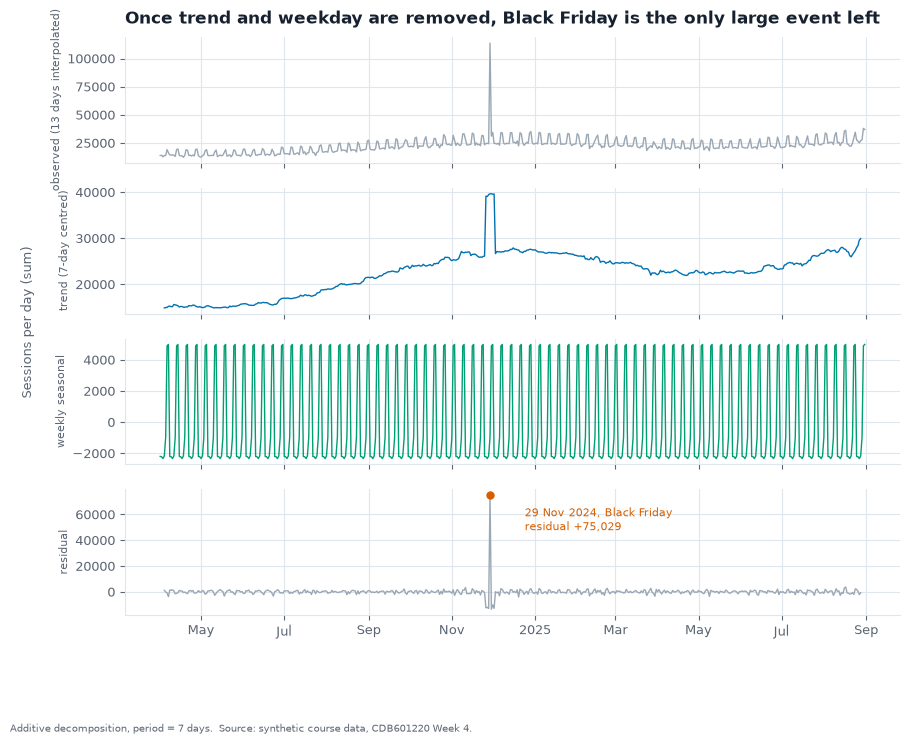

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, (name, s, col) in zip(axes, [("observed (13 days interpolated)", dec.observed, GREY),
                                     ("trend (7-day centred)", dec.trend, BLUE),
                                     ("weekly seasonal", dec.seasonal, GREEN),
                                     ("residual", dec.resid, GREY)]):
    ax.plot(s.index, s.values, color=col, lw=1)
    ax.set_ylabel(name, fontsize=8)
axes[3].annotate("29 Nov 2024, Black Friday\nresidual +75,029", (BF, dec.resid[BF]), xytext=(25, -8),
                 textcoords="offset points", fontsize=8, color=ORANGE, va="top")
axes[3].scatter([BF], [dec.resid[BF]], color=ORANGE, zorder=3)
axes[0].set_title("Once trend and weekday are removed, Black Friday is the only large event left")
fig.supylabel("Sessions per day (sum)", fontsize=9, color=SOFT)
save(fig, "b3_decomposition.png", "Additive decomposition, period = 7 days.")

In [8]:
try:
    seasonal_decompose(filled, model="additive", period=365)
except ValueError as err:
    print("period=365:", err)

period=365: x must have 2 complete cycles requires 730 observations. x only has 518 observation(s)


**Amplitude.** The weekly seasonal component swings **7,324 sessions a day** from trough (Wednesday) to
peak (Sunday). That's about a third of an average day.

**Largest residual: 29 November 2024**, +75,029, five times the next largest (+13,452, the day after).
Everything the trend and the weekday explain has been taken out, and the one thing left is Black Friday.
That's the event worth investigating, and it shows the residual panel is the useful one.

**With `period=365`, it won't run.** The series has 518 days, and an annual decomposition needs two full
cycles (730). That's the honest answer: one year of data can't separate an annual pattern from a one-off.
If it could run, the November build-up and Black Friday would move out of `resid` and into `seasonal`.
The spike would be relabelled "seasonal" on the strength of a single occurrence, with nothing to show it
repeats.

## 4 · Trailing or centred

In [9]:
lag_min = tslib.lag_at_turn(filled, 31, how="min")
lag_max = tslib.lag_at_turn(filled, 31, how="max")
for name, lg in [("low", lag_min), ("peak", lag_max)]:
    print(f"{name}: trailing {lg['trailing_turn'].date()}  centred {lg['centred_turn'].date()}  "
          f"lag {lg['lag_periods']} days  (half-window {lg['half_window']})")

low: trailing 2024-05-30  centred 2024-05-15  lag 15 days  (half-window 15)
peak: trailing 2024-12-29  centred 2024-12-14  lag 15 days  (half-window 15)


With a 31-day window, the trailing mean finds both turns, the May 2024 low and the December 2024 peak,
**15 days late**, exactly half the window (31 // 2 = 15). That's not a bug in the data. It's arithmetic,
because a trailing mean can't see a turn until the window has filled with post-turn days.

**A live dashboard has to show the trailing mean**, because a centred mean needs 15 days that haven't
happened yet. Its last 15 points would be missing, or quietly computed from a shrinking window. The caption
has to say so: *"31-day trailing mean. Turning points appear about 15 days after they happen."*

## 5 · The window is a claim

In [10]:
starts = pd.date_range("2024-04-01", periods=12, freq="MS")
windows = [7, 14, 28, 56, 91]


def slope(y):
    y = y.dropna()
    return np.polyfit((y.index - y.index[0]).days, y.values, 1)[0]


# Reading 1: the chart shows `w` days starting on the 1st of the start month.
view = pd.DataFrame({w: [slope(daily[s:s + pd.Timedelta(days=w - 1)]) for s in starts] for w in windows},
                    index=starts.strftime("%b %Y"))
# Reading 2: a w-day centred rolling mean, shown from the start month to the end of the series.
roll = pd.DataFrame({w: [slope(filled.rolling(w, center=True, min_periods=w // 2).mean()[s:]) for s in starts]
                     for w in windows}, index=starts.strftime("%b %Y"))

for name, t in [("chart window of w days", view), ("w-day rolling mean, start to end", roll)]:
    print(f"{name:34s} rising {(t > 0).sum().sum():2d}   falling {(t < 0).sum().sum():2d}   of {t.size}")
view.round(0).astype(int)

chart window of w days             rising 32   falling 28   of 60
w-day rolling mean, start to end   rising 39   falling 21   of 60


,7,14,28,56,91
Apr 2024,676,270,69,8,17
May 2024,315,25,16,21,42
Jun 2024,-1017,-194,-44,33,57
Jul 2024,982,274,105,84,83
Aug 2024,-212,84,40,74,74
Sep 2024,-60,64,89,68,124
Oct 2024,683,233,114,67,74
Nov 2024,-722,-76,-18,30,-19
Dec 2024,-118,0,23,-11,-34
Jan 2025,-230,-37,-23,-47,-52


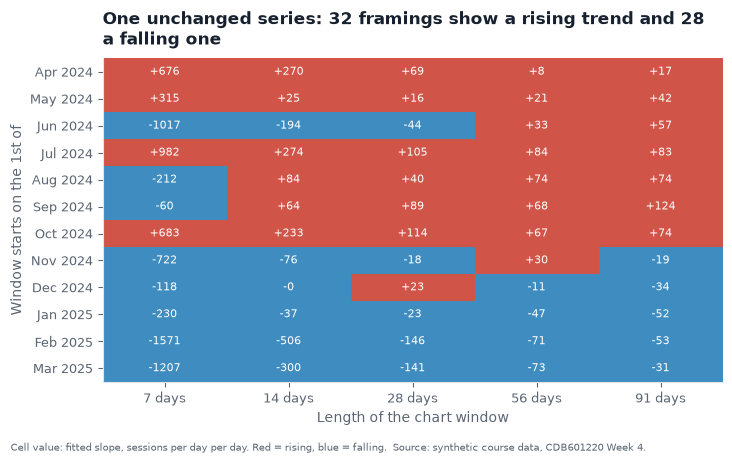

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(np.sign(view.values), cmap=PALETTE["diverging"], vmin=-1.6, vmax=1.6, aspect="auto")
for (i, j), v in np.ndenumerate(view.values):
    ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8, color="white")
ax.set_xticks(range(len(windows)), [f"{w} days" for w in windows])
ax.set_yticks(range(len(starts)), view.index)
ax.grid(False)
ax.set_xlabel("Length of the chart window")
ax.set_ylabel("Window starts on the 1st of")
ax.set_title(textwrap.fill("One unchanged series: 32 framings show a rising trend and 28 a falling one", 60))
save(fig, "b5_window_is_a_claim.png", "Cell value: fitted slope, sessions per day per day. Red = rising, blue = falling.")

The brief doesn't pin down what "window" means here, so I computed both readings and report both:

| Reading | Rising | Falling |
|---|---|---|
| The chart shows *w* days from the 1st of the start month (the framing an analyst chooses) | **32** | **28** |
| A *w*-day rolling mean drawn from the start month to the end | 39 | 21 |

Either way, one unchanged series supports **both** a rising and a falling story, depending only on where
the chart starts and how much it shows. In the second reading the window length hardly matters, since
smoothing doesn't move a fitted line much. The *start month* decides it.

**Why Tufte's Lie Factor can't be computed here.** The Lie Factor is (effect shown) / (effect in the
data), and that assumes there is one true "effect in the data" to divide by. A truncated bar has one: the
real ratio of two numbers. A cherry-picked window doesn't. The table above shows the trend *depends on*
the window, so there's no single denominator. Every framing is accurately drawn, and the lie is in which
one was picked. **The honest substitute is to publish the distribution:** say how many of the reasonable
framings agree with the one shown (here 32 of 60 rise), or show the whole series from its first recorded
day with the window fixed in advance, as Part E's ethics clause requires.